In [1]:
%pip install pandas matplotlib scikit-learn scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [3]:
#Load the dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1", sep=None, engine="python")

print(df.head())
print("Dataset Shape:", df.shape)
print("Missing Values:\n", df.isnull().sum().sum())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [4]:
#Prepare customer data
data = df.groupby("CUSTOMERNAME").agg({
    "SALES": "sum",
    "QUANTITYORDERED": "sum",
    "PRICEEACH": "mean",
    "ORDERNUMBER": "nunique"
}).reset_index()

data.columns = [
    "Customer", "TotalSales", "TotalQuantity",
    "AveragePrice", "TotalOrders"
]

print(data.head())

                  Customer  TotalSales  TotalQuantity  AveragePrice  \
0           AV Stores, Co.   157807.81           1778     77.947647   
1             Alpha Cognac    70488.44            687     85.097500   
2       Amica Models & Co.    94117.26            843     85.323462   
3  Anna's Decorations, Ltd   153996.13           1469     83.558043   
4        Atelier graphique    24179.96            270     79.775714   

   TotalOrders  
0            3  
1            3  
2            2  
3            4  
4            3  


In [5]:
#Normalize the data
X = data[["TotalSales", "TotalQuantity", "AveragePrice", "TotalOrders"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^

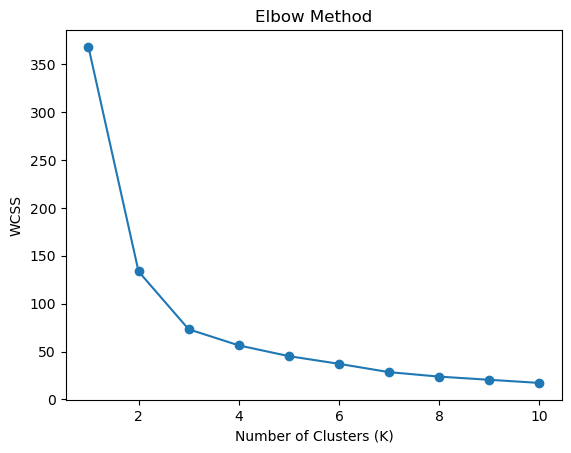

In [6]:
#Find the optimal number of clusters using the Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [7]:
#Apply K-Means clustering
k = 3

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
data["KMeansCluster"] = kmeans.fit_predict(X_scaled)

print(data[["Customer", "TotalSales", "KMeansCluster"]].head(10))
print("\nCustomers in each cluster:")
print(data["KMeansCluster"].value_counts().sort_index())

                       Customer  TotalSales  KMeansCluster
0                AV Stores, Co.   157807.81              0
1                  Alpha Cognac    70488.44              2
2            Amica Models & Co.    94117.26              2
3       Anna's Decorations, Ltd   153996.13              0
4             Atelier graphique    24179.96              0
5  Australian Collectables, Ltd    64591.46              0
6    Australian Collectors, Co.   200995.41              2
7   Australian Gift Network, Co    59469.12              2
8            Auto Assoc. & Cie.    64834.32              0
9              Auto Canal Petit    93170.66              0

Customers in each cluster:
KMeansCluster
0    42
1     2
2    48
Name: count, dtype: int64


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [8]:
#Apply Hierarchical Clustering
model = AgglomerativeClustering(n_clusters=k)
data["HierarchicalCluster"] = model.fit_predict(X_scaled)

print(data[["Customer", "HierarchicalCluster"]].head(10))
print("\nCustomers in each hierarchical cluster:")
print(data["HierarchicalCluster"].value_counts().sort_index())

                       Customer  HierarchicalCluster
0                AV Stores, Co.                    2
1                  Alpha Cognac                    0
2            Amica Models & Co.                    0
3       Anna's Decorations, Ltd                    0
4             Atelier graphique                    2
5  Australian Collectables, Ltd                    2
6    Australian Collectors, Co.                    0
7   Australian Gift Network, Co                    0
8            Auto Assoc. & Cie.                    2
9              Auto Canal Petit                    2

Customers in each hierarchical cluster:
HierarchicalCluster
0    66
1     2
2    24
Name: count, dtype: int64


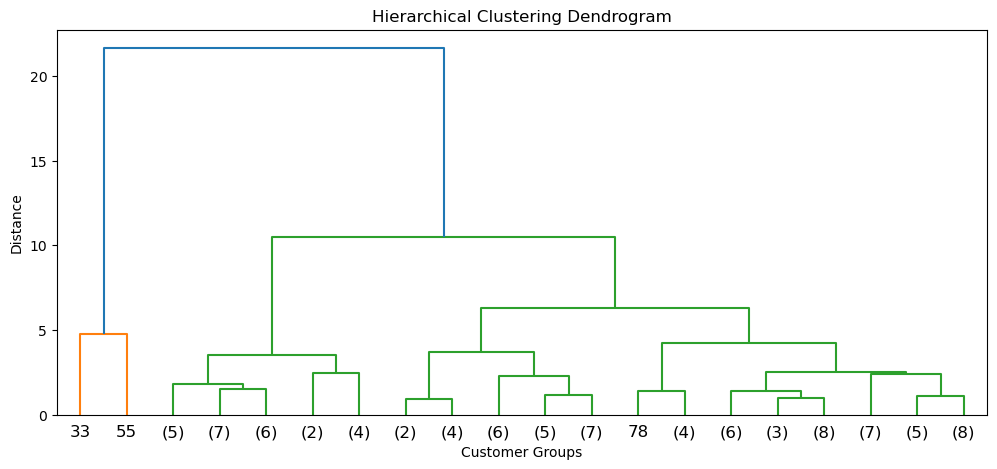

In [9]:
#Display the dendrogram
plt.figure(figsize=(12, 5))

Z = linkage(X_scaled, method="ward")
dendrogram(Z, truncate_mode="lastp", p=20)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer Groups")
plt.ylabel("Distance")
plt.show()

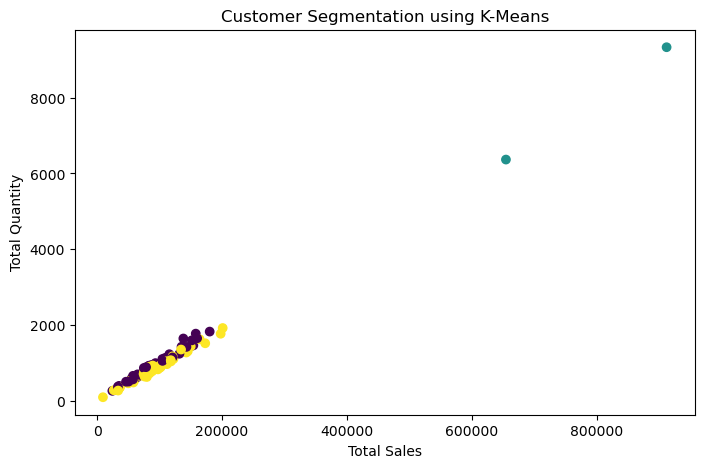

In [10]:
#Visualize the K-Means clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    data["TotalSales"],
    data["TotalQuantity"],
    c=data["KMeansCluster"],
    cmap="viridis"
)

plt.xlabel("Total Sales")
plt.ylabel("Total Quantity")
plt.title("Customer Segmentation using K-Means")
plt.show()